# 13 공통 코호트 재학습 — A/B/C 특징 비교

같은 train/validation에서 로지스틱 회귀와 CUDA XGBoost 6개를 새로 학습했습니다. 이전 모델의 점수만 잘라 비교한 실험이 아닙니다. 이 Notebook은 실제 결과 표시와 저장 모델 재검증을 수행하며 전체 재학습은 자동 실행하지 않습니다.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np,pandas as pd
from IPython.display import display,Image
from src.common import TABLES,CFG
assert Path(sys.executable).resolve()==Path(CFG['python']).resolve()
OUT=ROOT/'outputs/stage3'
def table(name): return pd.read_parquet(TABLES/('stage3_'+name+'.parquet'))
def figure(name): display(Image(filename=str(ROOT/('outputs/figures/stage3/'+name+'.png'))))
contract=json.loads((OUT/'source_contract.json').read_text(encoding='utf-8'))
assert contract['cohort']=='common' and contract['holdout_scored'] is False
display(json.loads((ROOT/'config/stage3_experiment.json').read_text(encoding='utf-8')))
print('실제 실행:',sys.executable)

{'scheme': 'temporal',
 'cohort': 'common',
 'H': 600,
 'L': 60,
 'families': ['A', 'B', 'C'],
 'models': ['logistic', 'xgboost'],
 'seed': 42,
 'parameter_policy': 'stage2와 같은 파라미터 및 조기 종료 규칙; 특징마다 새 전처리/모델 fit',
 'comparison_budgets_per_10000_raw': [5, 10, 20],
 'budget_meaning': '결과 확인 전에 정한 탐색용 공통 경보 부담 상한; 실제 운영 허용치 아님',
 'paired_bootstrap': '장비 번호01~10 군집(M01/M02 함께) 2000회 seed42; 선택된 임계값 고정',
 'holdout_scored': False}

실제 실행: C:\Users\fl27\anaconda3\envs\phm2018\python.exe


## 1. 같은 학습 행·정답·평가 시각

C의900 raw 이력까지 가용한 교집합입니다. 최대 가용 코호트보다 입력 커버리지가 줄어듭니다. 전체 기록 이벤트232개와 입력 있는53개를 구분합니다.

{'checks': [{'check': 'A train/validation 행·라벨·순서 및 공유 전처리 일치',
   'passed': True},
  {'check': 'B train/validation 행·라벨·순서 및 공유 전처리 일치', 'passed': True},
  {'check': 'C train/validation 행·라벨·순서 및 공유 전처리 일치', 'passed': True},
  {'check': 'A_logistic 저장 예측 전체 행·라벨 일치', 'passed': True},
  {'check': 'A_xgboost 저장 예측 전체 행·라벨 일치', 'passed': True},
  {'check': 'B_logistic 저장 예측 전체 행·라벨 일치', 'passed': True},
  {'check': 'B_xgboost 저장 예측 전체 행·라벨 일치', 'passed': True},
  {'check': 'C_logistic 저장 예측 전체 행·라벨 일치', 'passed': True},
  {'check': 'C_xgboost 저장 예측 전체 행·라벨 일치', 'passed': True}],
 'row_label_order_sha256': {'train': '5f30167a646655b378d2c6fe54368afa9200f7007fcc64ffa3abf11819d45365',
  'validation': 'aaaef5b878cef93f9f8671e5937ad0ff3c57af8c7735053d7a95b0c5e022fd63'},
 'paired_bootstrap': '10 장비 번호 군집(각 M01/M02를 함께) 2000회 seed42. 임계값 고정 조건부이며 선택 낙관/이력 불완전성 미보정.',
 'comparison_budgets': [5, 10, 20],
 'holdout_scored': False}

,partition,rows,positive,negative,NA,EXCLUDE
0,train_known,309273,1239,308034,0,0
1,validation_all,309203,392,6766,302002,43


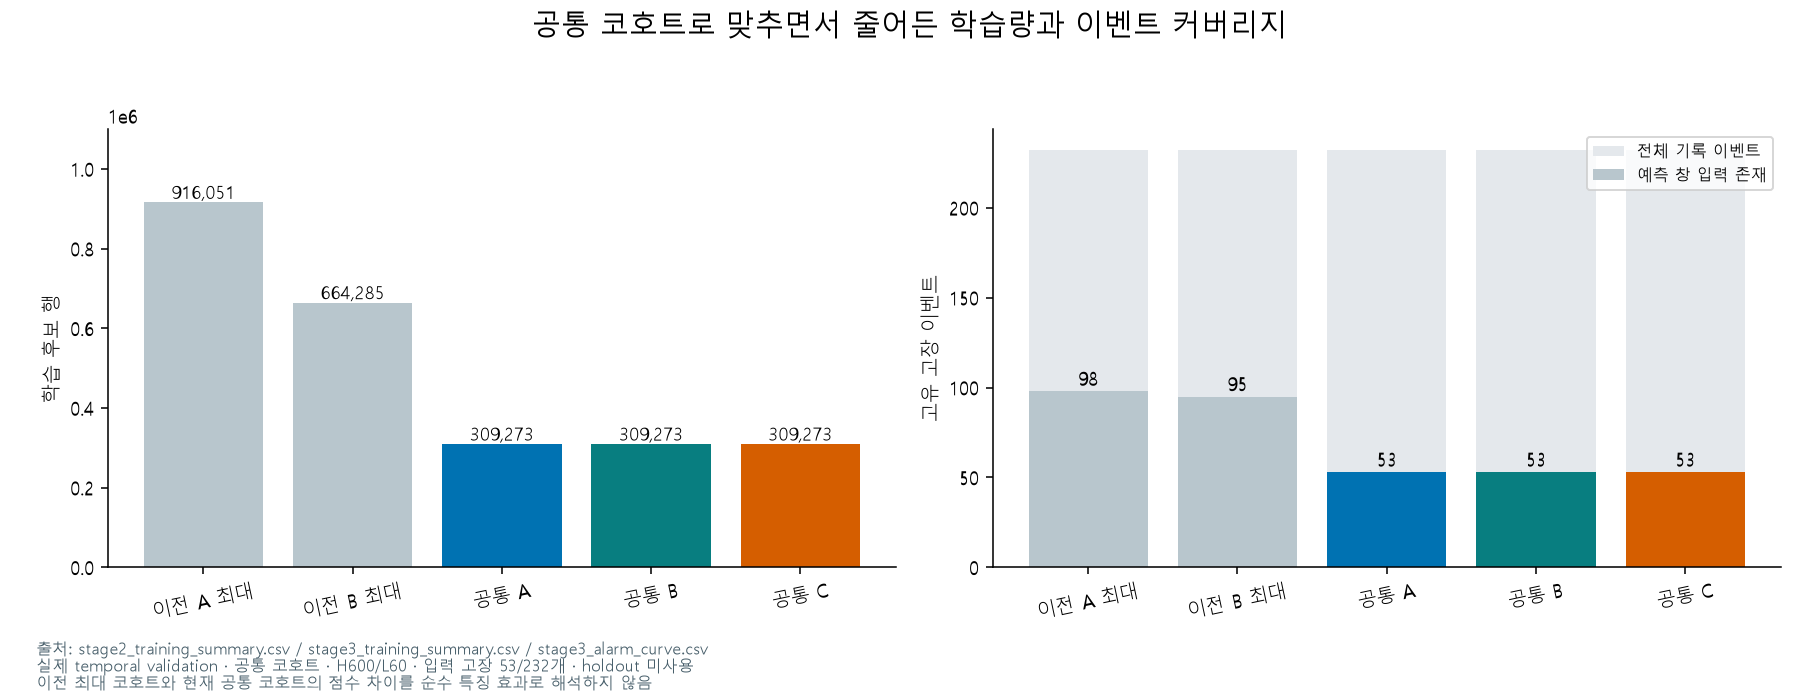

In [2]:
checks=json.loads((ROOT/'outputs/validation/stage3_common_contract.json').read_text(encoding='utf-8'))
assert all(c['passed'] for c in checks['checks'])
display(checks)
display(table('cohort_counts'))
figure('common_cohort')
runs=table('training_summary')
assert runs.train_rows.nunique()==runs.validation_all_rows.nunique()==runs.train_positive.nunique()==1

## 2. 실제 학습과 분류 보조 지표

숫자 표준화/범주 사전은 train만 fit했습니다. 같은 설정과 조기 종료 규칙을 적용했지만 채택 tree 수는 다릅니다. AP는 알려진 POS/NEG 후보에서만 계산합니다.

,run_id,feature_set,model,device,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,encoded_features,iterations,train_seconds,AP_known,ROC_AUC_known,log_loss_known,artifact_roundtrip_passed
0,A_logistic,A,logistic,cpu,309273,1239,309203,7158,392,233,77,0.918014,0.104289,0.268809,0.308452,True
1,A_xgboost,A,xgboost,cuda:0,309273,1239,309203,7158,392,233,53,0.498086,0.245622,0.585560,0.279724,True
2,B_logistic,B,logistic,cpu,309273,1239,309203,7158,392,257,126,2.557342,0.102549,0.283926,0.308509,True
3,B_xgboost,B,xgboost,cuda:0,309273,1239,309203,7158,392,257,36,0.930693,0.206897,0.513422,0.277394,True
4,C_logistic,C,logistic,cpu,309273,1239,309203,7158,392,269,151,3.616388,0.102989,0.297317,0.312445,True
5,C_xgboost,C,xgboost,cuda:0,309273,1239,309203,7158,392,269,14,0.984156,0.195928,0.543356,0.289038,True


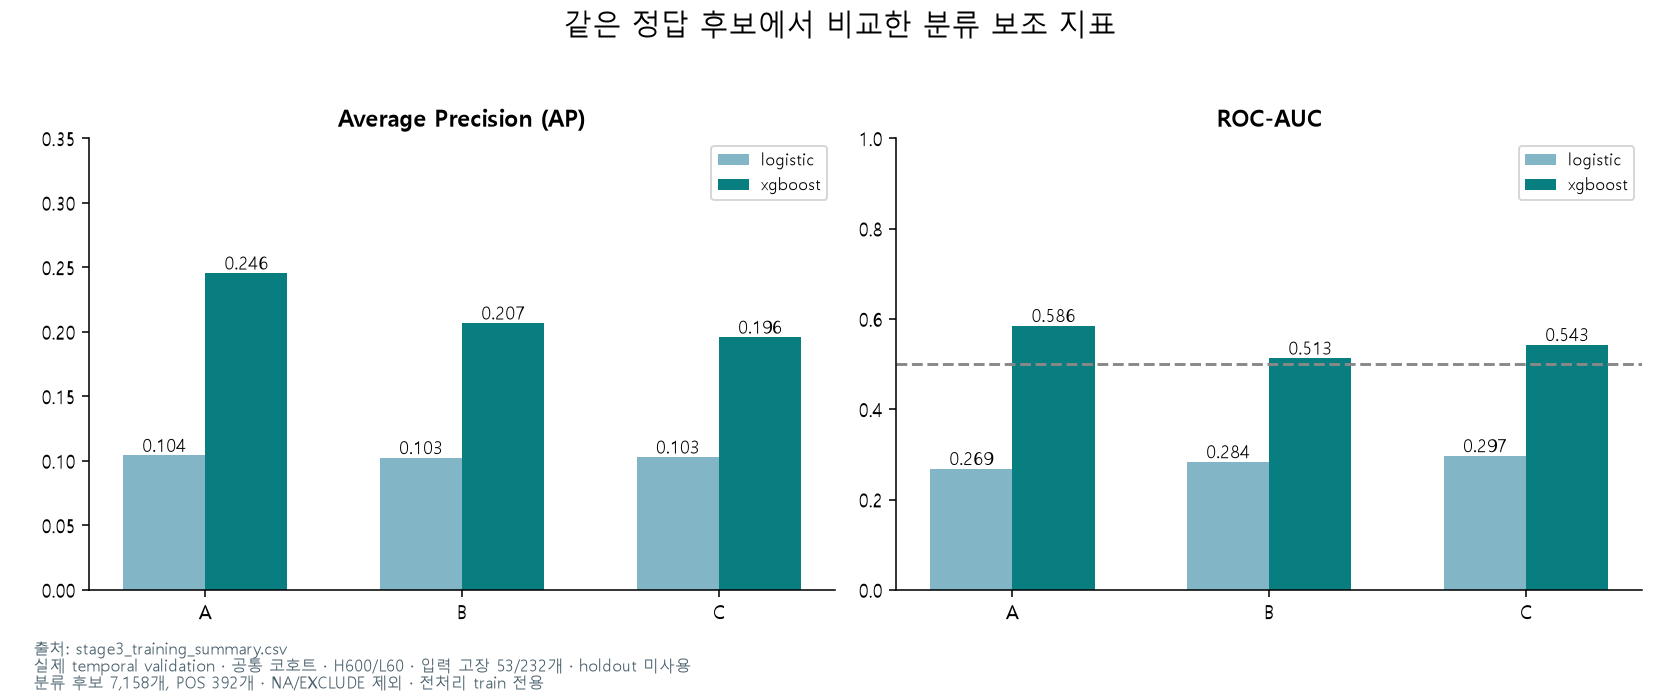

,run_id,label,rows,score_p50,score_p90,score_p99,unique_scores
0,A_logistic,NEG,6766,0.011577,0.092415,0.112345,6655
1,A_logistic,POS,392,0.004554,0.013642,0.718427,392
2,A_logistic,NA,302002,0.003309,0.009784,0.050172,272339
3,A_logistic,EXCLUDE,43,0.005034,0.013625,0.782410,43
4,A_xgboost,NEG,6766,0.005422,0.010821,0.014804,138
5,A_xgboost,POS,392,0.006284,0.018075,0.022543,105
6,A_xgboost,NA,302002,0.004469,0.013783,0.025852,3566
7,A_xgboost,EXCLUDE,43,0.006907,0.018672,0.047024,36
8,B_logistic,NEG,6766,0.012027,0.060491,0.107600,6730
9,B_logistic,POS,392,0.004462,0.017699,0.855659,390


A XGBoost 실제 학습 장치: cuda:0
B XGBoost 실제 학습 장치: cuda:0
C XGBoost 실제 학습 장치: cuda:0


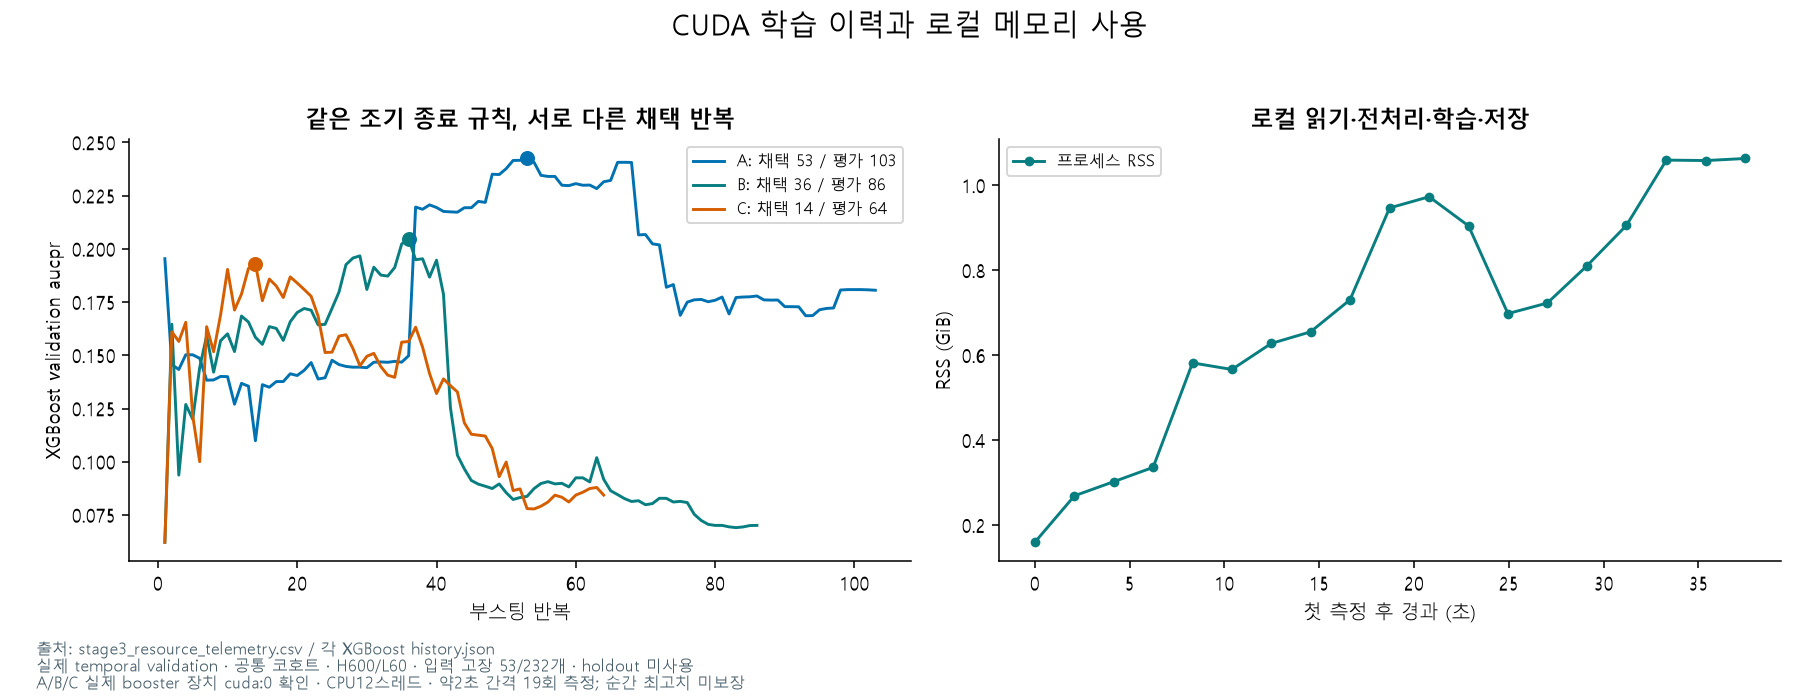

In [3]:
display(runs)
figure('classification')
display(table('score_states'))
for f in 'ABC':
    cfg=json.loads((OUT/f'{f}_xgboost_booster_config.json').read_text(encoding='utf-8'))
    assert cfg['learner']['generic_param']['device']=='cuda:0'
    print(f+' XGBoost 실제 학습 장치:',cfg['learner']['generic_param']['device'])
figure('training_resources')

## 3. 같은 경보 상한에서 비교

5/10/20회는 실험 전에 정한 비교용 상한이며 실제 운영 허용치가 아닙니다. 각 상한 아래에서 검출 수 최대, 동률이면 경보 부담 최소를 선택합니다. NA/EXCLUDE도 전체 점수화에 포함합니다.

,run_id,budget_per_10000_raw,threshold,detected_events,available_events,recall_available,recall_recorded,alarm_episodes_per_10000_raw,alarms_UNKNOWN_START,median_lead_raw
0,A_logistic,5,0.010031,7.0,53.0,0.132075,0.030172,2.699823,4474.0,258.0
1,A_logistic,10,0.000150,12.0,53.0,0.226415,0.051724,8.827681,15283.0,410.0
2,A_logistic,20,0.000150,12.0,53.0,0.226415,0.051724,8.827681,15283.0,410.0
3,A_xgboost,5,0.010000,9.0,53.0,0.169811,0.038793,3.527821,6080.0,346.0
4,A_xgboost,10,0.006907,17.0,53.0,0.320755,0.073276,6.135707,10610.0,310.0
5,A_xgboost,20,0.004555,19.0,53.0,0.358491,0.081897,11.445658,19933.0,332.0
6,B_logistic,5,0.005429,10.0,53.0,0.188679,0.043103,4.250427,7205.0,299.0
7,B_logistic,10,0.000163,12.0,53.0,0.226415,0.051724,9.062010,15700.0,410.0
8,B_logistic,20,0.000163,12.0,53.0,0.226415,0.051724,9.062010,15700.0,410.0
9,B_xgboost,5,0.006749,13.0,53.0,0.245283,0.056034,4.469620,7601.0,454.0


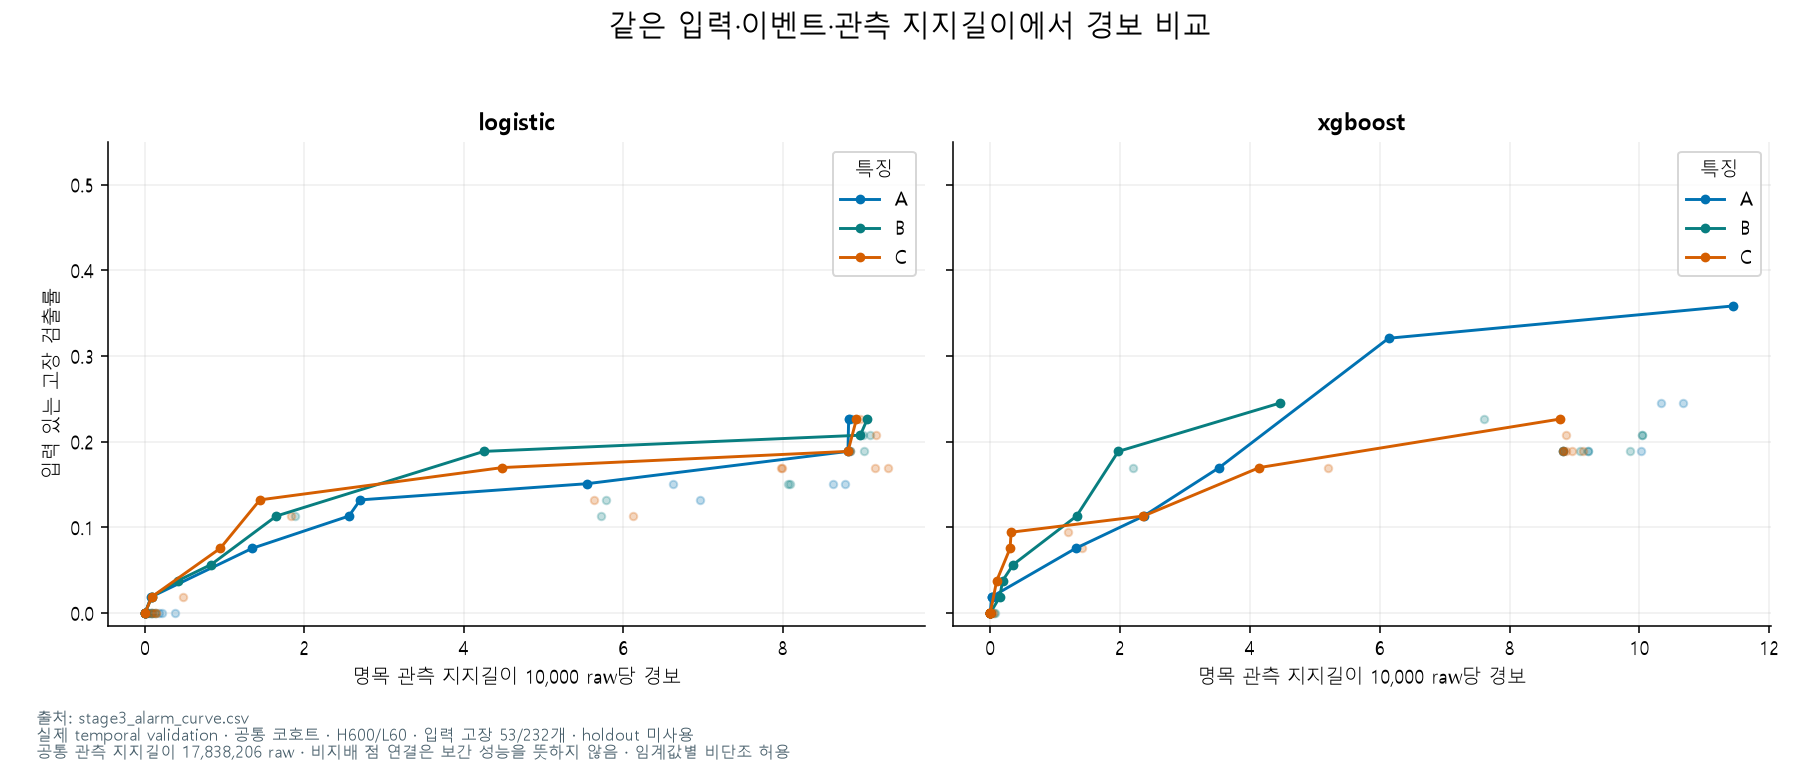

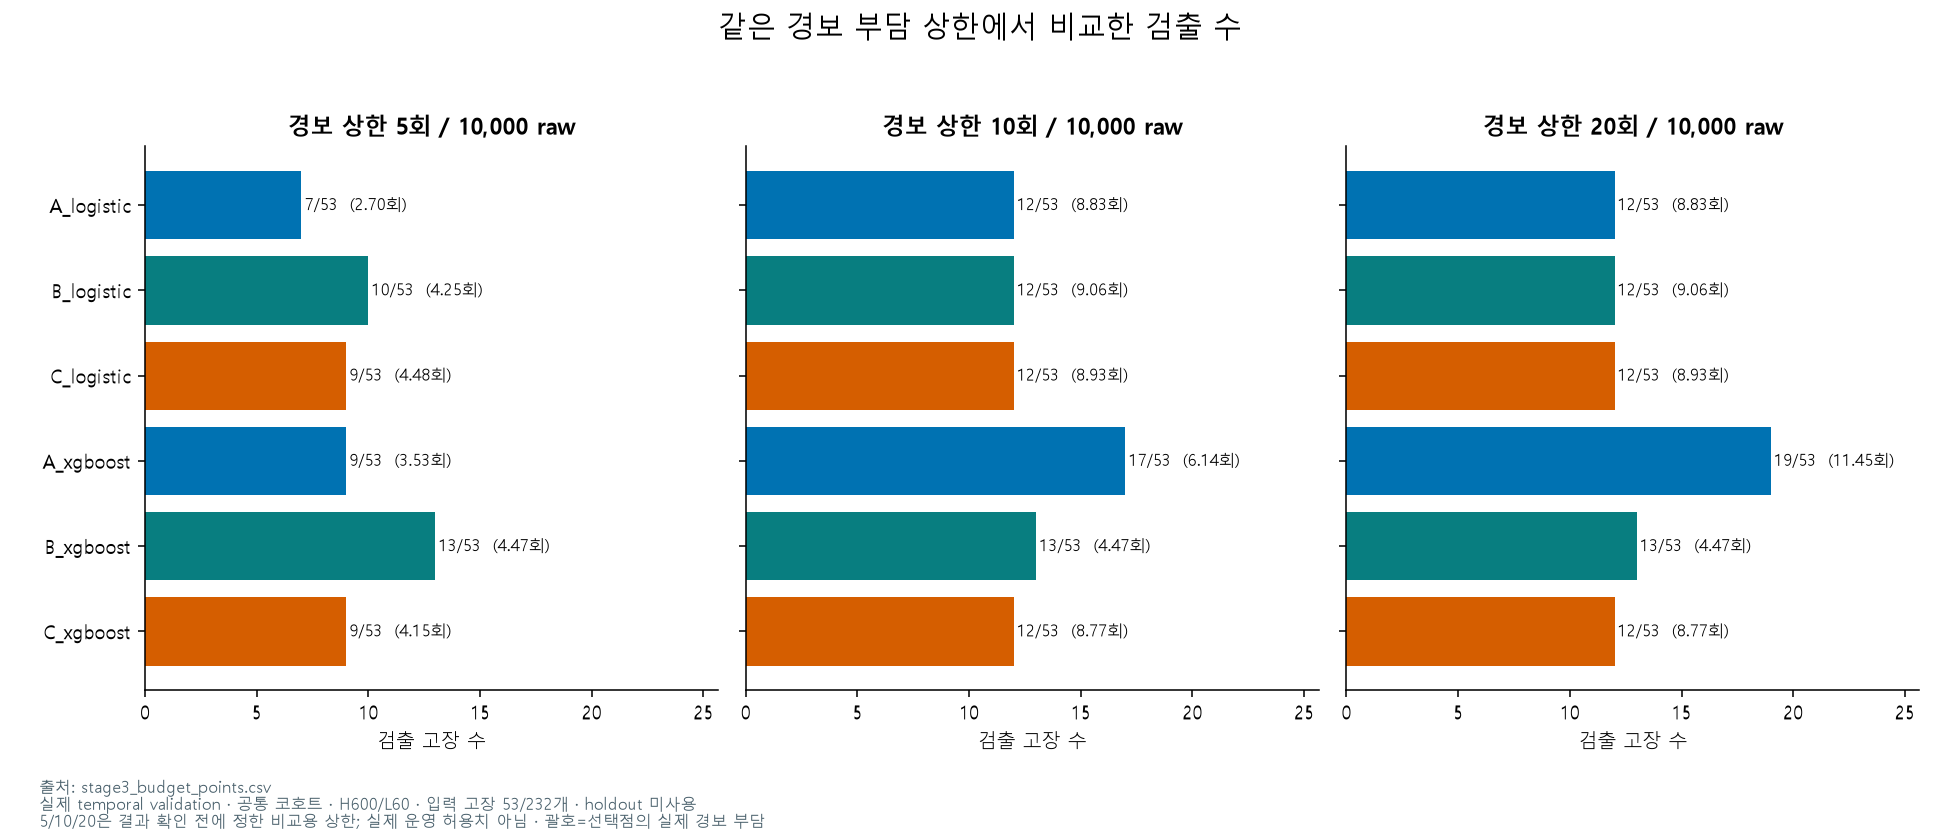

,run_id,threshold,detected_events,alarm_episodes_per_10000_raw
0,A_xgboost,0.040514,1.0,0.020742
1,C_xgboost,0.021731,2.0,0.099225
2,C_xgboost,0.017239,4.0,0.304963
3,C_xgboost,0.014471,5.0,0.321781
4,B_xgboost,0.016344,6.0,1.329730
5,B_xgboost,0.012544,10.0,1.972171
6,B_xgboost,0.006749,13.0,4.469620
7,A_xgboost,0.006907,17.0,6.135707
8,A_xgboost,0.004555,19.0,11.445658


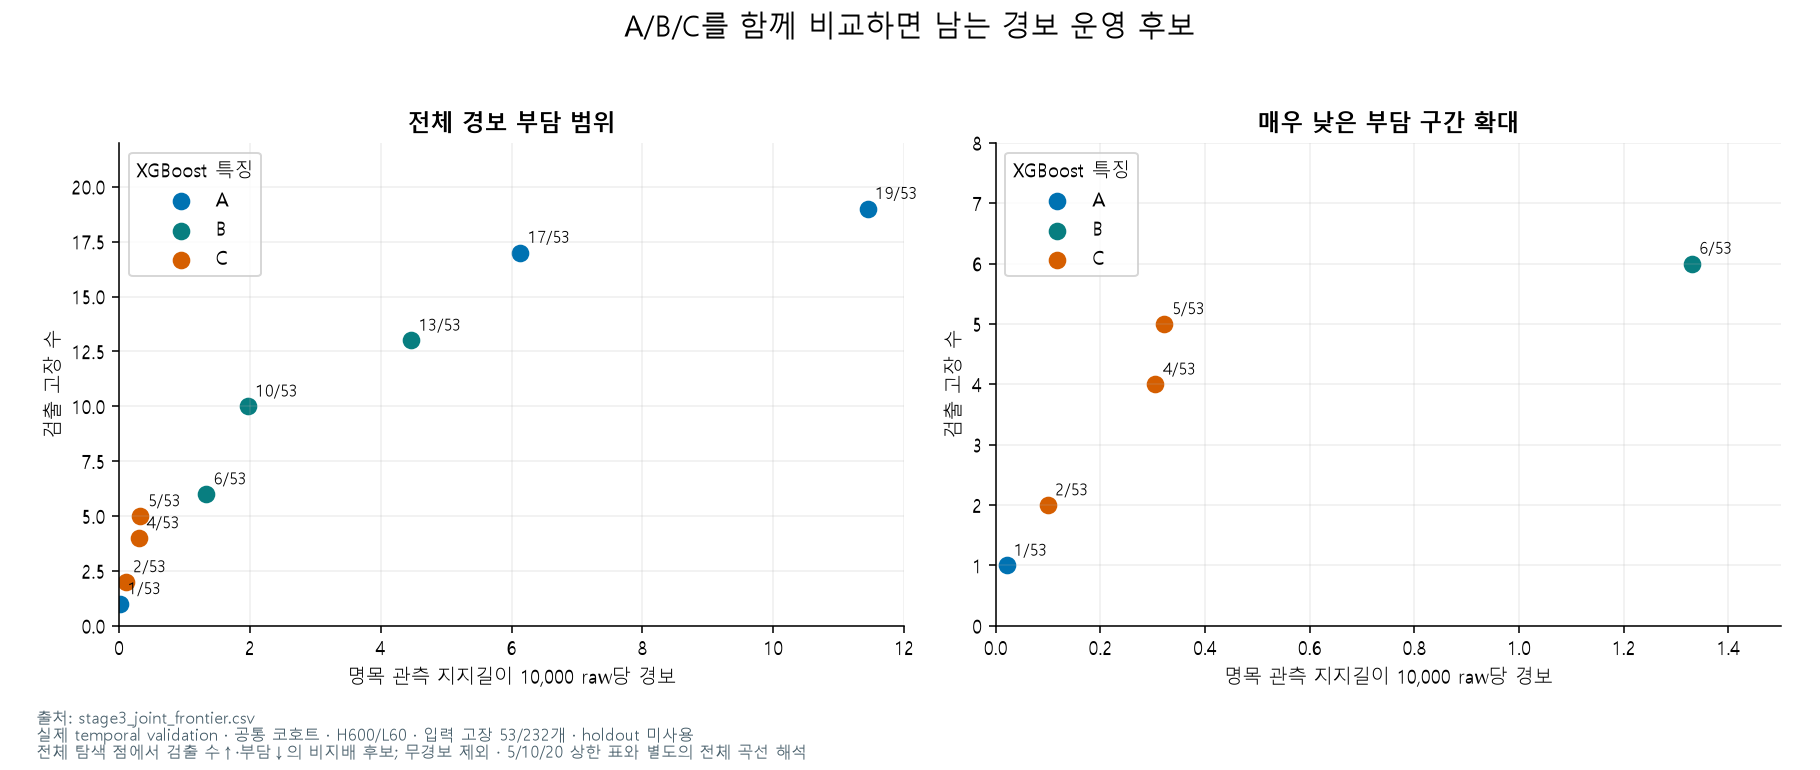

In [4]:
curve=table('alarm_curve');points=table('budget_points')
assert curve.available_events.nunique()==curve.observed_support_raw.nunique()==curve.available_anchors.nunique()==1
assert points.alarm_episodes_per_10000_raw.le(points.budget_per_10000_raw).all()
display(points[['run_id','budget_per_10000_raw','threshold','detected_events','available_events','recall_available','recall_recorded','alarm_episodes_per_10000_raw','alarms_UNKNOWN_START','median_lead_raw']])
figure('alarm_tradeoff')
figure('budget_comparison')
display(table('joint_frontier')[['run_id','threshold','detected_events','alarm_episodes_per_10000_raw']])
figure('joint_frontier')

## 4. 같은 이벤트의 대응 비교

01~10 장비 번호 군집을 재표집하고 M01/M02를 함께 유지합니다. 2,000회·seed42, 임계값 고정 조건부95% 구간입니다. 선택 낙관·다중 비교·불완전 고장 이력은 보정하지 않습니다.

,model,budget_per_10000_raw,comparison,detected_before,detected_after,gained_events,lost_events,recall_delta,ci_low,ci_high,valid_bootstrap_samples
0,logistic,5,B-A,7,10,7,4,0.056604,-0.034483,0.160032,2000
1,logistic,5,C-B,10,9,1,2,-0.018868,-0.072738,0.000000,2000
2,logistic,5,C-A,7,9,6,4,0.037736,-0.057185,0.136364,2000
3,logistic,10,B-A,12,12,0,0,0.000000,0.000000,0.000000,2000
4,logistic,10,C-B,12,12,1,1,0.000000,-0.042553,0.069809,2000
5,logistic,10,C-A,12,12,1,1,0.000000,-0.042553,0.069809,2000
6,logistic,20,B-A,12,12,0,0,0.000000,0.000000,0.000000,2000
7,logistic,20,C-B,12,12,1,1,0.000000,-0.042553,0.069809,2000
8,logistic,20,C-A,12,12,1,1,0.000000,-0.042553,0.069809,2000
9,xgboost,5,B-A,9,13,10,6,0.075472,-0.117647,0.190490,2000


,run_id,budget_per_10000_raw,denominator,recall,ci_low,ci_high,valid_bootstrap_samples,lead_p10,lead_median
0,A_logistic,5,available,0.132075,0.052609,0.218750,2000,103.6,258.0
1,A_logistic,5,recorded,0.030172,0.013036,0.071445,2000,103.6,258.0
2,A_logistic,10,available,0.226415,0.105236,0.372104,2000,258.6,410.0
3,A_logistic,10,recorded,0.051724,0.024388,0.105067,2000,258.6,410.0
4,A_logistic,20,available,0.226415,0.105236,0.372104,2000,258.6,410.0
5,A_logistic,20,recorded,0.051724,0.024388,0.105067,2000,258.6,410.0
6,A_xgboost,5,available,0.169811,0.048368,0.359043,2000,110.8,346.0
7,A_xgboost,5,recorded,0.038793,0.009732,0.135816,2000,110.8,346.0
8,A_xgboost,10,available,0.320755,0.162775,0.500000,2000,128.4,310.0
9,A_xgboost,10,recorded,0.073276,0.030294,0.176489,2000,128.4,310.0


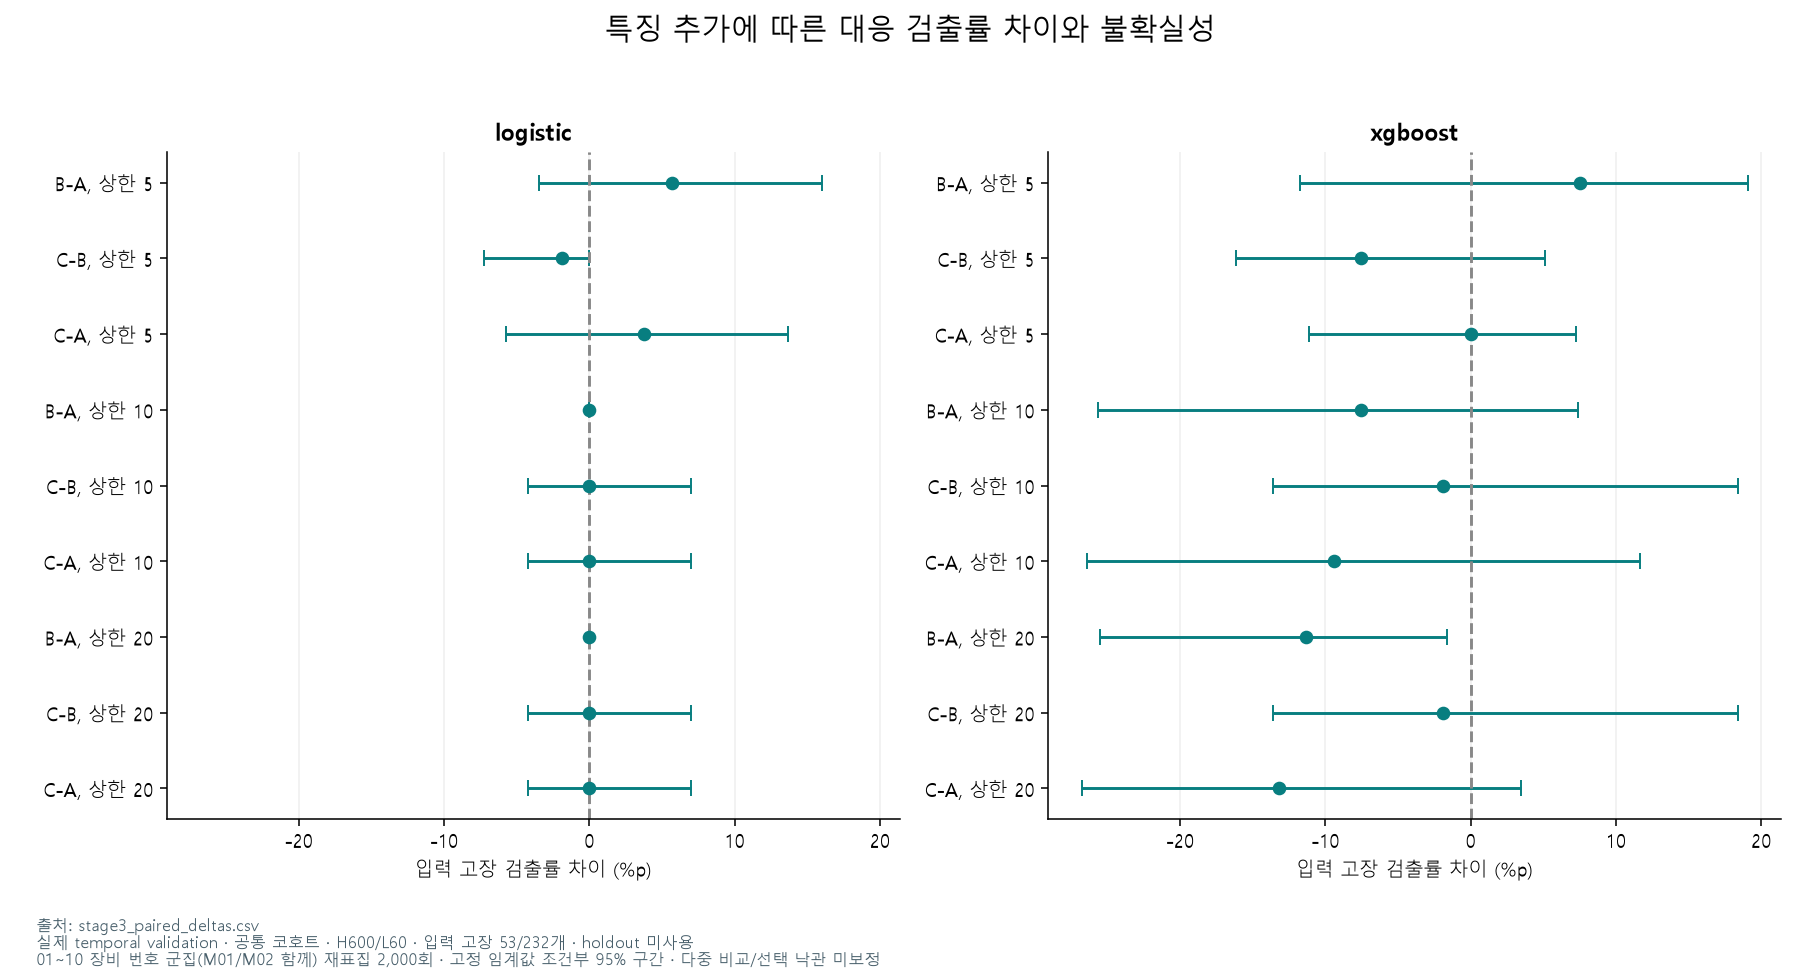

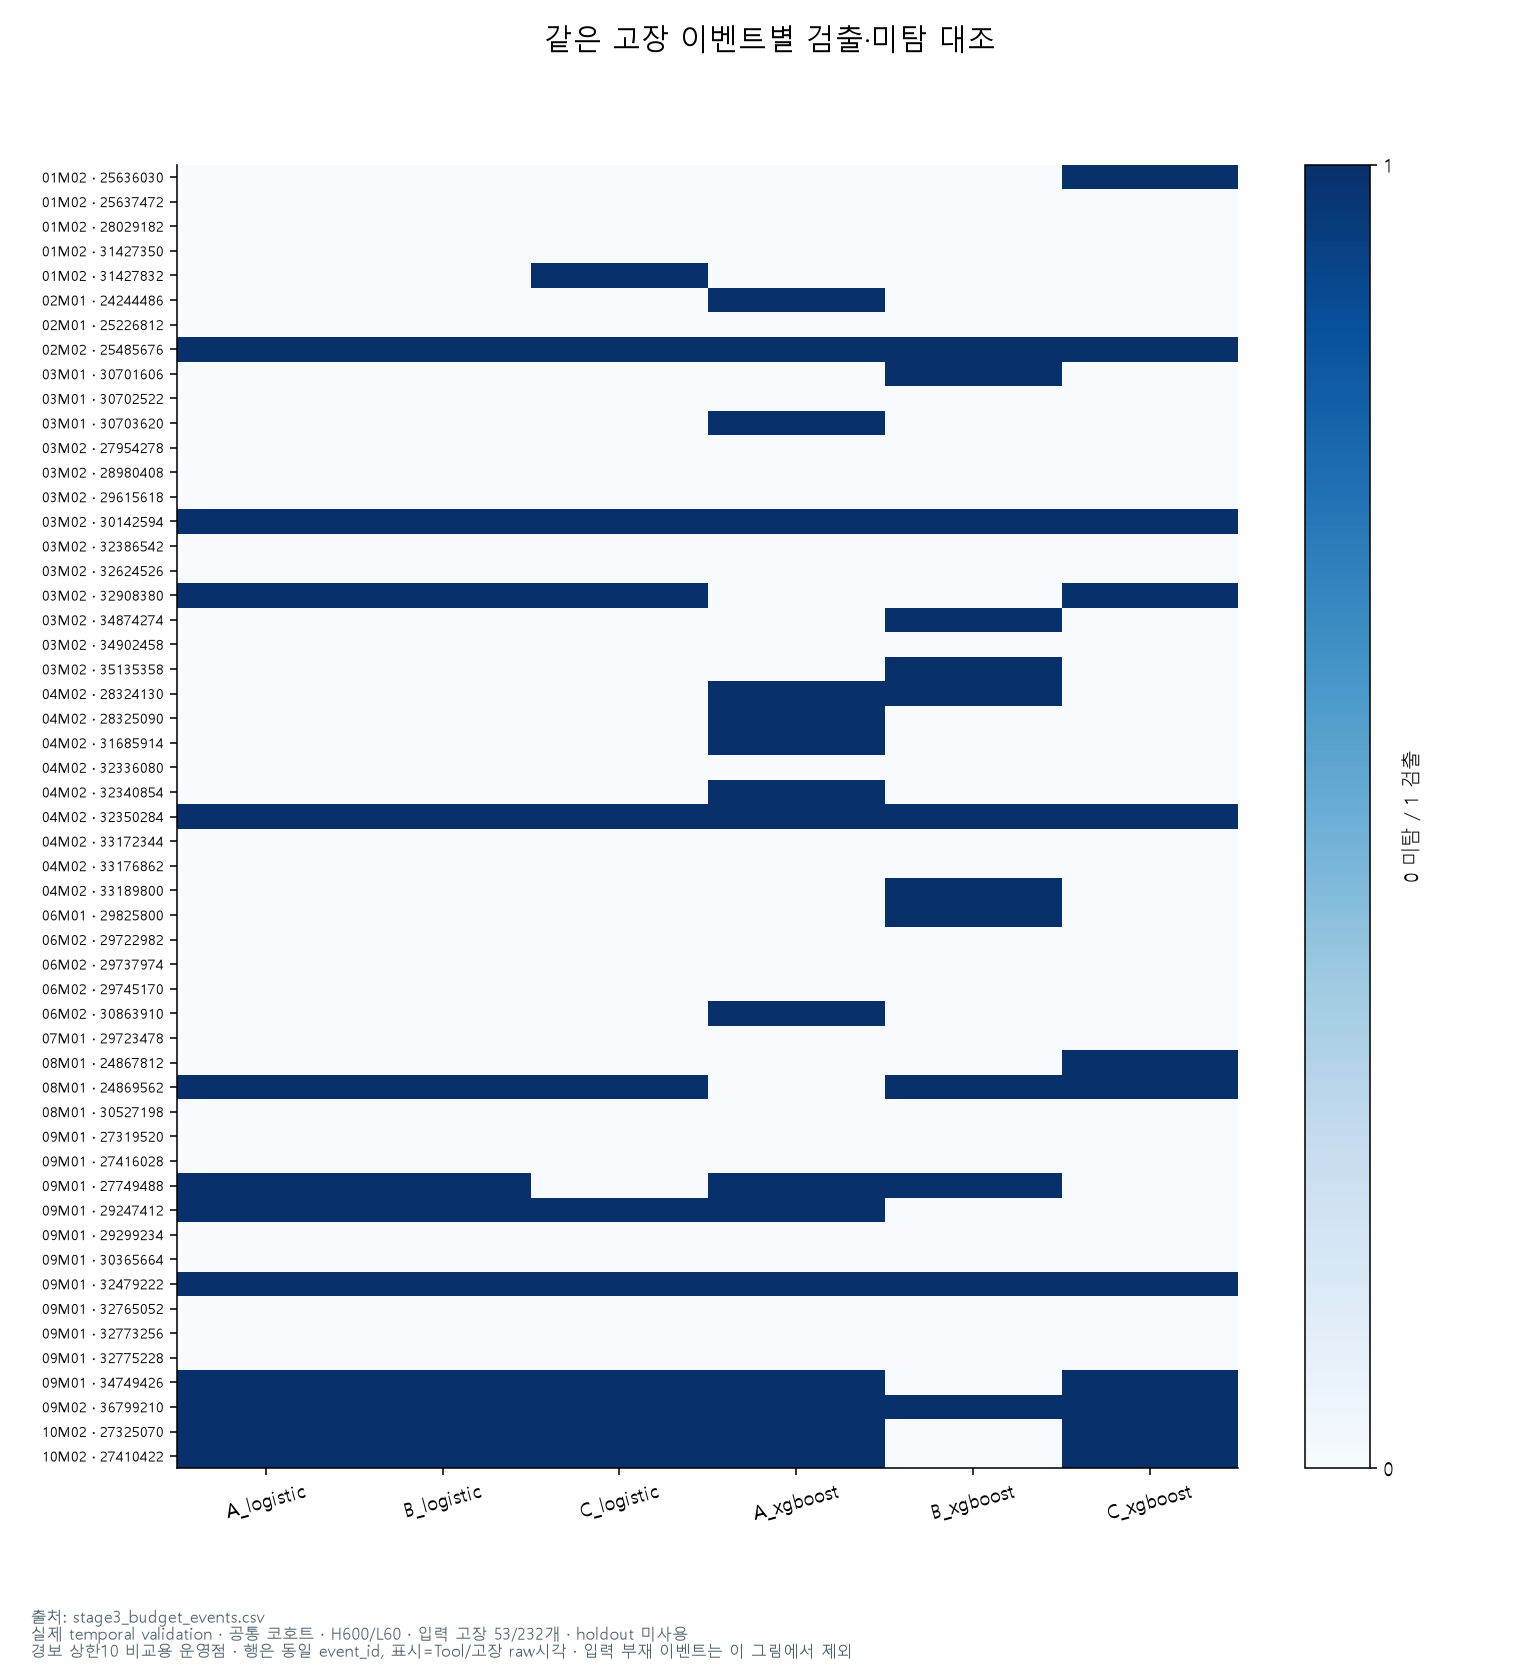

행렬은 상한10에서 입력 있는 동일53개 고장을 모두 표시합니다.


In [5]:
display(table('paired_deltas'))
display(table('uncertainty'))
figure('paired_differences')
figure('event_matrix')
print('행렬은 상한10에서 입력 있는 동일53개 고장을 모두 표시합니다.')

## 5. 저장 모델로 실제 공통 입력을 다시 예측

각 특징의 첫 배치128행을 다시 읽습니다. 새 fit 없이 저장 전처리의 transform만 사용하고 6개 모델 예측이 원래 저장 점수와 일치하는지 확인합니다.

In [6]:
import joblib,xgboost as xgb
from src.pretraining import iter_scoring_batches
from src.features import schema
reference=None
for f in 'ABC':
    X,meta=next(iter_scoring_batches('temporal','validation',f,600,'common'))
    X=X.iloc[:128];meta=meta.iloc[:128]
    assert list(X)==schema()[f]
    assert not {'time','Tool','audit_label','TTF'} & set(X)
    if reference is None: reference=meta
    else: pd.testing.assert_frame_equal(reference,meta)
    prep=joblib.load(OUT/f'{f}_preprocessor.joblib')
    transformed=prep.transform(X).astype('float32')
    for kind in ['logistic','xgboost']:
        rid=f'{f}_{kind}';model=joblib.load(OUT/(rid+'.joblib'))
        if kind=='xgboost': score=model.get_booster().predict(xgb.DMatrix(transformed),iteration_range=(0,model.best_iteration+1))
        else: score=model.predict_proba(transformed)[:,1]
        saved=pd.read_parquet(OUT/(rid+'_validation.parquet'),columns=['Tool','time','score'])
        expected=meta[['Tool','time']].merge(saved,on=['Tool','time'],how='left',validate='one_to_one')
        np.testing.assert_allclose(score,expected.score,rtol=1e-6,atol=1e-7)
        print(rid,': 실제 재계산 일치',len(score),'행')

A_logistic : 실제 재계산 일치 128 행


A_xgboost : 실제 재계산 일치 128 행
B_logistic : 실제 재계산 일치 128 행


B_xgboost : 실제 재계산 일치 128 행
C_logistic : 실제 재계산 일치 128 행


C_xgboost : 실제 재계산 일치 128 행


## 해석과 다음 방향

공통 코호트에서는 비교용 경보 상한5에서 B XGBoost(13/53)가 A(9/53)보다 많이 검출했고, 상한10에서는 A(17/53)가 B(13/53)보다 많이 검출했습니다. C는 정해 둔5/10/20 상한에서 앞서지 않았지만 매우 낮은 경보 부담(약0.32회/10,000 raw, 검출5/53)에서는 비지배 후보로 남습니다. 대응 차이의 불확실성이 큽니다. A/B를 주 조정 후보로 유지하고 C의 저부담 참조 후보도 보존하며, 제한적 깊이·양성 가중치 조정 및 seed 민감도를 다음 단계로 권합니다.

현재 결과는 validation 탐색이며 독립 일반화 성능이 아닙니다. 최대 가용 코호트와 공통 코호트의 점수를 단순 비교하지 않습니다. holdout은 모델·경보 규칙·운영점 고정 후 평가합니다. 시간 단위·정비 종료·이력 완전성·점수의 확률 보정은 미검증입니다.